In [1]:
import networkx as nx
import numpy as np
import random
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
def create_network(num_nodes=25, radius=0.4):
    G = nx.random_geometric_graph(num_nodes, radius)
    for u, v in G.edges():
        G[u][v]['weight'] = round(random.uniform(1, 10), 2)
    return G

G = create_network()
pos = nx.get_node_attributes(G, 'pos')


In [3]:
source = int(input("Enter source node: "))
destination = int(input("Enter destination node: "))


In [ ]:
def flooding_path(G, src, dst):
    try:
        # Flooding illustrated as simple shortest path for demo purposes
        return nx.shortest_path(G, src, dst)
    except (nx.NetworkXNoPath, nx.NodeNotFound):
        return None


In [ ]:
def lorawan_path(G, src, dst):
    try:
        # LoRaWAN demo: prefer low-hop routes (use shortest path)
        return nx.shortest_path(G, src, dst)
    except (nx.NetworkXNoPath, nx.NodeNotFound):
        return None


In [ ]:
# Placeholder: OLSR removed in this project configuration
def placeholder_removed():
    pass


In [7]:
def compute_metrics(G, path):
    hops = len(path) - 1
    delay = sum(G[path[i]][path[i+1]]['weight'] for i in range(hops))
    throughput = 1024 / delay
    packet_loss = random.uniform(0.01, 0.05) * hops
    energy = hops * random.uniform(0.8, 1.2)
    return hops, delay, throughput, packet_loss, energy


In [ ]:
algorithms = {
    "Flooding": flooding_path,
    "LoRaWAN": lorawan_path
}

paths = {}
results = []

for name, algo in algorithms.items():
    try:
        path = algo(G, source, destination)
        paths[name] = path
        hops, delay, thr, loss, energy = compute_metrics(G, path)
        results.append([name, hops, delay, thr, loss, energy])
    except:
        paths[name] = None


In [10]:
df = pd.DataFrame(results, columns=[
    "Algorithm", "Hop Count", "Delay",
    "Throughput", "Packet Loss", "Energy"
])
df


,Algorithm,Hop Count,Delay,Throughput,Packet Loss,Energy
0,Dijkstra,3,8.27,123.821040,0.096331,3.051839
1,OLSR,3,13.39,76.474981,0.030376,2.795169


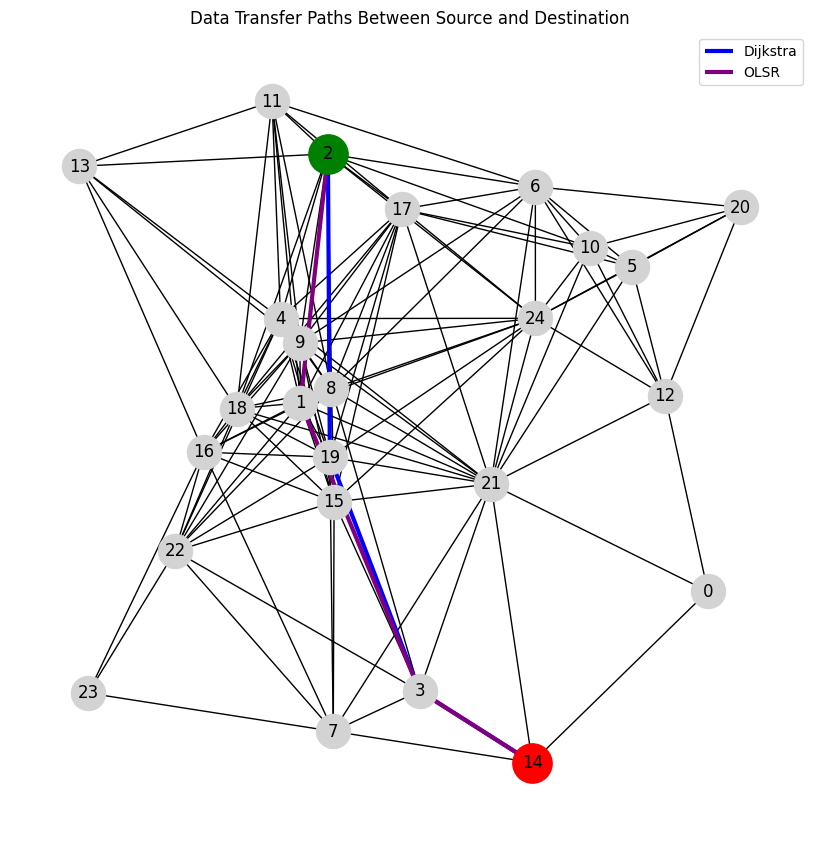

In [ ]:
plt.figure(figsize=(8,8))

# Draw base network
nx.draw(G, pos, node_color='lightgray', node_size=600, with_labels=True)

# Highlight source & destination
nx.draw_networkx_nodes(G, pos, nodelist=[source], node_color='green', node_size=800)
nx.draw_networkx_nodes(G, pos, nodelist=[destination], node_color='red', node_size=800)

# Algorithm colors
colors = {
    "Flooding": "blue",
    "LoRaWAN": "green"
}

# Draw paths
for algo, path in paths.items():
    if path:
        edges = [(path[i], path[i+1]) for i in range(len(path)-1)]
        nx.draw_networkx_edges(
            G, pos,
            edgelist=edges,
            width=3,
            edge_color=colors[algo],
            label=algo
        )

plt.legend()
plt.title("Data Transfer Paths Between Source and Destination")
plt.show()
